# Neural Network Section -> LSTM Quantile Regression for VaR

This notebook is the deep learning part of the study. The goal is to estimate the **1% quantile** of S&P 500 daily returns (i.e. our **99% VaR**) using an LSTM trained with a quantile (pinball) loss.

The rough flow:
1. Load the returns series and take a quick look at it
2. Scale the returns (z-score) and reshape into 20-day lookback sequences
3. Build and train the LSTM with the quantile loss
4. Check for overfitting via the learning curves
5. Generate out-of-sample VaR forecasts, unscale them, and compute the violation rate

Runs on a GPU runtime in Colab.

In [ ]:
import pandas as pd
import numpy as np
import tensorflow as tf

print(tf.__version__)
print(tf.config.list_physical_devices("GPU"))

2.20.0
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

# Output locations for figures/tables used in the results section,
# alongside the existing predictions CSV output.
OUTPUT_DIR = "/content/drive/MyDrive/VaR-LSTM/outputs"
FIG_DIR = os.path.join(OUTPUT_DIR, "figures")
TBL_DIR = os.path.join(OUTPUT_DIR, "tables")
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TBL_DIR, exist_ok=True)

In [ ]:
input_path = "/content/drive/MyDrive/VaR-LSTM/sp500_lstm_input.csv"
df = pd.read_csv(input_path)

required_cols = ["Date", "Return", "Regime"]
missing_cols = sorted(set(required_cols) - set(df.columns))
if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

df["Date"] = pd.to_datetime(df["Date"], errors="raise")
if df["Date"].duplicated().any():
    raise ValueError("Input contains duplicate dates.")
if not df["Date"].is_monotonic_increasing:
    raise ValueError("Input dates must be strictly increasing.")
if not np.isfinite(df["Return"]).all():
    raise ValueError("Input returns contain missing or non-finite values.")

print(f"Loaded {len(df)} returns from {df['Date'].min().date()} to {df['Date'].max().date()}")
df.head()

Loaded 5283 returns from 2004-01-05 to 2024-12-30


,Date,Return,Regime
0,2004-01-05,0.012319,Calm
1,2004-01-06,0.001291,Calm
2,2004-01-07,0.002364,Calm
3,2004-01-08,0.004951,Calm
4,2004-01-09,-0.008927,Calm


In [ ]:
df.shape

(5283, 3)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5283 entries, 0 to 5282
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    5283 non-null   datetime64[ns]
 1   Return  5283 non-null   float64       
 2   Regime  5283 non-null   object        
dtypes: datetime64[ns](1), float64(1), object(1)
memory usage: 123.9+ KB


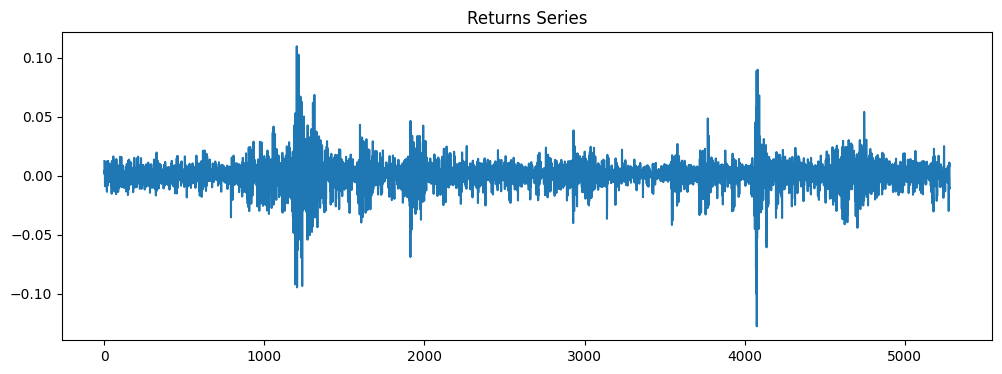

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,4))
plt.plot(df["Return"])
plt.title("Returns Series")
plt.savefig(os.path.join(FIG_DIR, "01_returns_series.png"), dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
df = df.dropna(subset=["Return"]).reset_index(drop=True)

df.head(), df.shape

(        Date    Return Regime
 0 2004-01-05  0.012319   Calm
 1 2004-01-06  0.001291   Calm
 2 2004-01-07  0.002364   Calm
 3 2004-01-08  0.004951   Calm
 4 2004-01-09 -0.008927   Calm,
 (5283, 3))

Lets try Standard Scaler to improve results.

In [ ]:
from sklearn.preprocessing import StandardScaler

# The scaler is re-fit inside each walk-forward block below using only
# observations available before that block's first forecast.

In [ ]:
# Walk-forward periodic-refit setup

# Instead of a single 80-20 split, we refit the LSTM every
# refit_every days on all data available up to that point
# (expanding window) and forecast the next block one-step-ahead.
# This produces one 99% VaR per date after the burn-in. Model weights
# are fixed within each block, while each forecast sequence uses only
# returns observed before its target date.

lookback = 20        # Prespecified primary sequence length
refit_every = 250    # Prespecified periodic refit interval (~annually)
burn_in = 1000       # initial training obs; first forecast ~2008 (GFC out-of-sample)
q = 0.01             # 1% quantile -> 99% VaR

returns_raw = df["Return"].to_numpy()
n_obs = len(returns_raw)

print(f"Observations:      {n_obs}")
print(f"lookback={lookback}, refit_every={refit_every}, burn_in={burn_in}, q={q}")

Observations:      5283
lookback=20, refit_every=250, burn_in=1000, q=0.01


In [ ]:
def make_sequences(scaled_series, target_indices, lookback):
    """Build (X, y) sequences for the given target indices.

    The sequence predicting the return at index i uses
    scaled_series[i - lookback:i], i.e. strictly PAST observations,
    so there is no look-ahead leakage.
    """
    X, y = [], []
    for i in target_indices:
        X.append(scaled_series[i - lookback:i])
        y.append(scaled_series[i])
    X = np.array(X).reshape(-1, lookback, 1)
    y = np.array(y)
    return X, y

In [ ]:
# Where the walk-forward starts / how many dates it covers
first_forecast_date = df["Date"].iloc[burn_in]
print(f"First forecast date (approx): {first_forecast_date}")
print(f"Total forecast dates:         {n_obs - burn_in}")
print(f"Number of refit blocks:       {len(range(burn_in, n_obs, refit_every))}")

First forecast date (approx): 2007-12-24 00:00:00
Total forecast dates:         4283
Number of refit blocks:       18


In [ ]:
def quantile_loss(q):
  """uses the "maximum" trick to represent the piecewise linear quantile loss function in a single line."""
  def loss(y_true, y_pred):
      e = y_true - y_pred
      return tf.reduce_mean(tf.maximum(q * e, (q - 1) * e))
  return loss

In [ ]:
q = 0.01

In [ ]:
def build_model(lookback):
    """Fresh stacked-LSTM quantile-regression model for one refit block.

    Seeds are reset inside so every block starts from the same nominal
    initialization. GPU kernels can still introduce small op-level
    nondeterminism, which is retained as a disclosed limitation.
    """
    tf.random.set_seed(42)
    np.random.seed(42)

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(lookback, 1)),
        tf.keras.layers.LSTM(64, return_sequences=True),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.LSTM(32),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(16, activation="relu"),
        tf.keras.layers.Dense(1),
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss=quantile_loss(q),
    )
    return model

## Walk-Forward Periodic Refit

Rather than training once on an 80-20 split, we walk forward through the series:

- Start after a **burn-in** of `burn_in` observations (so the first forecast is ~2008 and the GFC is a genuine out-of-sample test).
- Every `refit_every` days, refit a **fresh** model on **all data up to that point** (expanding window), then forecast the next block one-step-ahead.
- The `StandardScaler` is re-fit inside each block on that block's **training data only**, so there is no leakage.
- Each date gets exactly one 99% VaR, giving full 2008-2024 coverage aligned to `results_df`.

The architecture per block is the same stacked LSTM as before: `LSTM(64) -> Dropout -> LSTM(32) -> Dropout -> Dense(16) -> Dense(1)`, quantile (pinball) loss at q=0.01, Adam, early stopping on validation loss.

In [ ]:
from sklearn.preprocessing import StandardScaler

pred_dates = []
pred_actual_raw = []
pred_var = []
histories = []

block_starts = list(range(burn_in, n_obs, refit_every))

for b, block_start in enumerate(block_starts):
    block_end = min(block_start + refit_every, n_obs)

    # Fit scaler on TRAINING data only: indices [0, block_start)
    scaler = StandardScaler()
    scaler.fit(returns_raw[:block_start].reshape(-1, 1))
    scaled = scaler.transform(returns_raw.reshape(-1, 1)).flatten()

    # Training sequences: targets in [lookback, block_start)
    X_tr, y_tr = make_sequences(scaled, range(lookback, block_start), lookback)

    # Fresh model + early stopping for this block
    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=15, restore_best_weights=True
    )
    model = build_model(lookback)
    h = model.fit(
        X_tr, y_tr,
        epochs=100, batch_size=32,
        validation_split=0.2, shuffle=False,
        verbose=0, callbacks=[early_stop],
    )
    histories.append(h)

    # Forecast this block one-step-ahead: targets [block_start, block_end)
    fc_targets = list(range(block_start, block_end))
    X_fc, _ = make_sequences(scaled, fc_targets, lookback)
    var_scaled = model.predict(X_fc, verbose=0).flatten()

    # Inverse-transform to return space with THIS block's scaler
    var_unscaled = scaler.inverse_transform(var_scaled.reshape(-1, 1)).flatten()

    for j, i in enumerate(fc_targets):
        pred_dates.append(df["Date"].iloc[i])
        pred_actual_raw.append(returns_raw[i])
        pred_var.append(var_unscaled[j])

    print(f"Block {b + 1:>2}/{len(block_starts)}: "
          f"train<{block_start}, forecast [{block_start}:{block_end}) "
          f"({block_end - block_start} days), epochs={len(h.history['loss'])}")

Block  1/18: train<1000, forecast [1000:1250) (250 days), epochs=17
Block  2/18: train<1250, forecast [1250:1500) (250 days), epochs=16
Block  3/18: train<1500, forecast [1500:1750) (250 days), epochs=53
Block  4/18: train<1750, forecast [1750:2000) (250 days), epochs=45
Block  5/18: train<2000, forecast [2000:2250) (250 days), epochs=42
Block  6/18: train<2250, forecast [2250:2500) (250 days), epochs=42
Block  7/18: train<2500, forecast [2500:2750) (250 days), epochs=36
Block  8/18: train<2750, forecast [2750:3000) (250 days), epochs=41
Block  9/18: train<3000, forecast [3000:3250) (250 days), epochs=67
Block 10/18: train<3250, forecast [3250:3500) (250 days), epochs=61
Block 11/18: train<3500, forecast [3500:3750) (250 days), epochs=55
Block 12/18: train<3750, forecast [3750:4000) (250 days), epochs=55
Block 13/18: train<4000, forecast [4000:4250) (250 days), epochs=57
Block 14/18: train<4250, forecast [4250:4500) (250 days), epochs=42
Block 15/18: train<4500, forecast [4500:4750) (2

In [ ]:
# Assemble walk-forward predictions (already in return space)
lstm_results = pd.DataFrame({
    "Date": pred_dates,
    "Return": pred_actual_raw,
    "VaR_LSTM_99": pred_var,
    "Lookback": lookback,
})

lstm_results["Viol_LSTM_99"] = (
    lstm_results["Return"] < lstm_results["VaR_LSTM_99"]
).astype(int)

print("Forecast rows:", lstm_results.shape[0])
print("Coverage:", lstm_results["Date"].min(), "->", lstm_results["Date"].max())
lstm_results.head()

Forecast rows: 4283
Coverage: 2007-12-24 00:00:00 -> 2024-12-30 00:00:00


,Date,Return,VaR_LSTM_99,Lookback,Viol_LSTM_99
0,2007-12-24,0.008045,-0.019348,20,0
1,2007-12-26,0.000808,-0.019370,20,0
2,2007-12-27,-0.014385,-0.019348,20,0
3,2007-12-28,0.001503,-0.019321,20,0
4,2007-12-31,-0.006875,-0.019333,20,0


## Overfitting Analysis (per refit block)

Each block trains an independent model with early stopping on a validation tail, so we check the train/validation gap **per block** rather than for a single fit.

Below we plot the learning curves for the **final** refit block (the largest training set) and print the final train/val loss and gap for **every** block. A small, stable gap across blocks indicates the walk-forward is fitting healthily; a gap that widens in later blocks would flag overfitting as the training set grows.

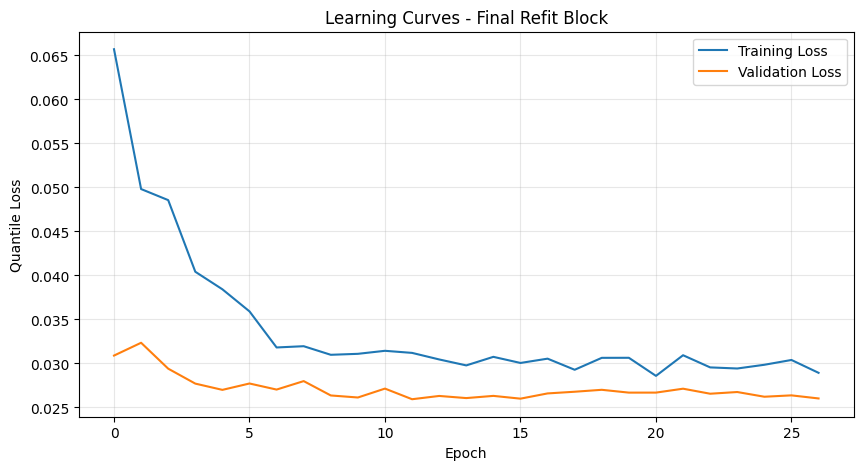

Per-block fit summary:
  Block  1: epochs= 17, train=0.02824, val=0.08285, gap=+0.05461
  Block  2: epochs= 16, train=0.02081, val=0.22995, gap=+0.20914
  Block  3: epochs= 53, train=0.02074, val=0.04068, gap=+0.01994
  Block  4: epochs= 45, train=0.02674, val=0.02512, gap=-0.00162
  Block  5: epochs= 42, train=0.02585, val=0.03198, gap=+0.00614
  Block  6: epochs= 42, train=0.02719, val=0.03021, gap=+0.00302
  Block  7: epochs= 36, train=0.05049, val=0.03779, gap=-0.01270
  Block  8: epochs= 41, train=0.02734, val=0.02036, gap=-0.00698
  Block  9: epochs= 67, train=0.02733, val=0.02258, gap=-0.00475
  Block 10: epochs= 61, train=0.02701, val=0.02524, gap=-0.00177
  Block 11: epochs= 55, train=0.02669, val=0.02469, gap=-0.00200
  Block 12: epochs= 55, train=0.02757, val=0.02641, gap=-0.00117
  Block 13: epochs= 57, train=0.02808, val=0.02482, gap=-0.00326
  Block 14: epochs= 42, train=0.02594, val=0.04253, gap=+0.01659
  Block 15: epochs= 30, train=0.02780, val=0.04135, gap=+0.01355
  

,Block,Epochs,Train_Loss,Val_Loss,Gap
0,1,17,0.028236,0.082849,0.054614
1,2,16,0.020813,0.229952,0.209139
2,3,53,0.020743,0.040678,0.019936
3,4,45,0.026739,0.025117,-0.001622
4,5,42,0.025846,0.031985,0.006139
5,6,42,0.027192,0.030215,0.003023
6,7,36,0.050492,0.037792,-0.012700
7,8,41,0.027335,0.020356,-0.006980
8,9,67,0.027335,0.022584,-0.004751
9,10,61,0.027013,0.025241,-0.001772


In [ ]:
import matplotlib.pyplot as plt

# Learning curves for the final (largest) refit block
h_last = histories[-1]
plt.figure(figsize=(10, 5))
plt.plot(h_last.history["loss"], label="Training Loss")
plt.plot(h_last.history["val_loss"], label="Validation Loss")
plt.title("Learning Curves - Final Refit Block")
plt.xlabel("Epoch")
plt.ylabel("Quantile Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig(os.path.join(FIG_DIR, "02_learning_curves_final_block.png"), dpi=150, bbox_inches="tight")
plt.show()

# Train/val gap for every block
print("Per-block fit summary:")
block_summary_rows = []
for k, h in enumerate(histories):
    ft = h.history["loss"][-1]
    fv = h.history["val_loss"][-1]
    print(f"  Block {k + 1:>2}: epochs={len(h.history['loss']):>3}, "
          f"train={ft:.5f}, val={fv:.5f}, gap={fv - ft:+.5f}")
    block_summary_rows.append({
        "Block": k + 1,
        "Epochs": len(h.history["loss"]),
        "Train_Loss": ft,
        "Val_Loss": fv,
        "Gap": fv - ft,
    })

block_summary_df = pd.DataFrame(block_summary_rows)
block_summary_df.to_csv(os.path.join(TBL_DIR, "01_per_block_fit_summary.csv"), index=False)
block_summary_df

In [ ]:
# Descriptive out-of-sample violation rate. Formal UC, independence and
# conditional-coverage tests are calculated in VaR_Main.R.
print("Overall violation rate:", lstm_results["Viol_LSTM_99"].mean())
print("Forecast period:", lstm_results["Date"].min(), "->", lstm_results["Date"].max())
lstm_results.head()

Overall violation rate: 0.019845902404856407
Forecast period: 2007-12-24 00:00:00 -> 2024-12-30 00:00:00


,Date,Return,VaR_LSTM_99,Lookback,Viol_LSTM_99
0,2007-12-24,0.008045,-0.019348,20,0
1,2007-12-26,0.000808,-0.019370,20,0
2,2007-12-27,-0.014385,-0.019348,20,0
3,2007-12-28,0.001503,-0.019321,20,0
4,2007-12-31,-0.006875,-0.019333,20,0


In [ ]:
# Descriptive annual violation counts. These do not replace the formal
# Christoffersen independence test in VaR_Main.R.
lstm_results["Year"] = pd.to_datetime(lstm_results["Date"]).dt.year
yearly_violations = lstm_results.groupby("Year")["Viol_LSTM_99"].agg(["mean", "sum", "count"])
yearly_violations.to_csv(os.path.join(TBL_DIR, "02_yearly_violation_rate.csv"))
yearly_violations

,mean,sum,count
Year,,,
2007,0.000000,0,5
2008,0.166008,42,253
2009,0.031746,8,252
2010,0.007937,2,252
2011,0.007937,2,252
2012,0.000000,0,250
2013,0.000000,0,252
2014,0.000000,0,252
2015,0.007937,2,252


## Export

Predictions are already in the original return scale (each block inverse-transforms with its own scaler), so we can export directly. The CSV is written to Drive and read back into `VaR_Main.R`, where the LSTM is backtested (Kupiec + Christoffersen) alongside the other models on the shared date set.

In [ ]:
# Distributional sanity check for the predicted return quantile. A small
# number of positive forecasts is not automatically invalid when the
# conditional 1% return quantile is positive.
lstm_results["VaR_LSTM_99"].describe()

,VaR_LSTM_99
count,4283.000000
mean,-0.027497
std,0.011579
min,-0.099080
25%,-0.031698
50%,-0.023831
75%,-0.019833
max,-0.012524


In [ ]:
# Export walk-forward predictions for VaR_Main.R

output_path = "/content/drive/MyDrive/VaR-LSTM/lstm_var_predictions_20_scaled.csv"

export_cols = ["Date", "Return", "VaR_LSTM_99", "Lookback", "Viol_LSTM_99"]
if lstm_results["Date"].duplicated().any():
    raise ValueError("Predictions contain duplicate dates.")
if not lstm_results["Date"].is_monotonic_increasing:
    raise ValueError("Prediction dates are not strictly increasing.")
if not np.isfinite(lstm_results[["Return", "VaR_LSTM_99"]].to_numpy()).all():
    raise ValueError("Predictions contain missing or non-finite values.")
expected_viol = (lstm_results["Return"] < lstm_results["VaR_LSTM_99"]).astype(int)
if not expected_viol.equals(lstm_results["Viol_LSTM_99"]):
    raise ValueError("Violation indicators are inconsistent with returns and VaR.")

lstm_results[export_cols].to_csv(output_path, index=False, date_format="%Y-%m-%d")

print("Saved to:", output_path)
print("Rows:", len(lstm_results))
print("Overall violation rate:", lstm_results["Viol_LSTM_99"].mean())
lstm_results[export_cols].head()

Saved to: /content/drive/MyDrive/VaR-LSTM/lstm_var_predictions_20_scaled.csv
Rows: 4283
Overall violation rate: 0.019845902404856407


,Date,Return,VaR_LSTM_99,Lookback,Viol_LSTM_99
0,2007-12-24,0.008045,-0.019348,20,0
1,2007-12-26,0.000808,-0.019370,20,0
2,2007-12-27,-0.014385,-0.019348,20,0
3,2007-12-28,0.001503,-0.019321,20,0
4,2007-12-31,-0.006875,-0.019333,20,0


In [ ]:
lstm_results.tail()

,Date,Return,VaR_LSTM_99,Lookback,Viol_LSTM_99,Year
4278,2024-12-23,0.007261,-0.034352,20,0,2024
4279,2024-12-24,0.010982,-0.031095,20,0,2024
4280,2024-12-26,-0.000406,-0.027312,20,0,2024
4281,2024-12-27,-0.011117,-0.026043,20,0,2024
4282,2024-12-30,-0.010760,-0.028145,20,0,2024
